# Fractal detection on COCO and AI-GenBench

This notebook runs the package on **local photographs and generated images**, with
**500 COCO real + 500 AI-GenBench fake images** by default. It saves its plots, numeric
measurements, models, configurations, logs, and MLflow runs. The saved cell outputs
show the completed demonstration; use **Restart Kernel and Run All** to repeat it.
For the data results, start at **section 9**: it contains class statistics, labeled
real/synthetic examples, errors, and comparison plots. Section 10 explains both classes.

| Section | Features demonstrated |
| --- | --- |
| 1–3 | Recursive discovery, metadata sampling, 1:1 labels, explicit disjoint splits |
| 4–6 | All 21 features, dimension fits, Gaussian/SVD residuals, C/NumPy parity |
| 7–8 | CSV, path/embedded-image Parquet, configuration-driven supervised training |
| 9–11 | Results, real/fake galleries, mistakes, class statistics, fit quality, ROC/confusion matrix, explanations |
| 12–14 | Multiple directories, bounded prediction, CLI, error handling, extraction, logs |
| 15–16 | MLflow tracking/UI/Projects, larger runs, reproducible output inventory |

This is a **demonstration experiment**, not the official AI-GenBench evaluation protocol.
COCO photographs and this multi-source fake collection differ in content, resolution,
and encoding. A classifier can exploit those differences. Its scores here do not establish
general detection performance or prove that an individual image is synthetic.

## 1. Environment and paths

From `Fractal-synthetic-image-detector`, install and launch:

```console
uv sync --locked --extra mlflow --group notebooks
uv run --locked --extra mlflow --group notebooks jupyter lab notebooks/coco_aigenbench_demo.ipynb
```

Select the project's `.venv` interpreter if using VS Code. The data is expected at
`../data/coco/{train2017,val2017}` and `../data/AI-GenBench-fake_part/data/*.parquet`.
Set `FRACTAL_DEMO_DATA` or edit `DATA_DIR` for another location. No data is downloaded.

In [1]:
import json
import logging
import os
import platform
import subprocess
import sys
from datetime import UTC, datetime
from importlib.metadata import version
from itertools import islice
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import yaml
from IPython.display import display
from mlflow.tracking import MlflowClient
from PIL import Image, ImageOps
from scipy.special import expit
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

from fractal_detector import (
    DataSource,
    Detector,
    FeatureConfig,
    FeatureResult,
    ImageFailure,
    TaskConfig,
    TrackingConfig,
    TrackingRun,
    TrainingConfig,
    configure_logging,
    evaluate_features,
    extract,
    fit_features,
    iter_manifest,
    iter_sources,
    load_config,
    native_available,
    read_manifest,
    run_config,
    run_task,
    train,
)
from fractal_detector.features import noise_residual
from fractal_detector.io import load_image

candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / "Fractal-synthetic-image-detector"]
PROJECT = next(p for p in candidates if (p / "src/fractal_detector").is_dir())
DATA_DIR = Path(os.environ.get("FRACTAL_DEMO_DATA", str(PROJECT.parent / "data"))).resolve()
PER_CLASS = 500
SEED = 1337
WORKERS = min(4, os.cpu_count() or 1)
BATCH_SIZE = 16
OUTPUT_ROOT = PROJECT / "outputs/notebook-demo"
RUN_DIR = OUTPUT_ROOT / datetime.now(UTC).strftime("run-%Y%m%dT%H%M%S%fZ")
RUN_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 70)

print(f"Python {platform.python_version()} | C extension: {native_available()}")
print(f"Data: {DATA_DIR}\nOutputs: {RUN_DIR}")
display(
    pd.Series(
        {
            name: version(name)
            for name in (
                "fractal-image-detector",
                "numpy",
                "scikit-learn",
                "pyarrow",
                "mlflow",
                "jupyterlab",
            )
        },
        name="installed version",
    ).to_frame()
)

2026/09/24 06:24:45 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at D:\Pulpit\Fractal-Image-Detector\Fractal-synthetic-image-detector\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Python 3.14.7 | C extension: True
Data: D:\Pulpit\Fractal-Image-Detector\data
Outputs: D:\Pulpit\Fractal-Image-Detector\Fractal-synthetic-image-detector\outputs\notebook-demo\run-20260924T042445924723Z


,installed version
fractal-image-detector,0.1.0
numpy,2.5.3
scikit-learn,1.9.1
pyarrow,25.0.1
mlflow,3.16.0
jupyterlab,4.6.3


## 2. Build a reproducible 1:1 sample

The small helper `demo_data.py` reads **metadata columns only** to inventory all fake
shards and recursively lists COCO JPEGs. It joins records linked through
`paired_real_images`, including their COCO photographs. A seeded hash assigns each
connected group to a 60/20/20 pool. We then take exactly the same number of real and
fake images from each pool, rotating through generators to avoid sampling one shard
or generator exclusively.

The notebook creates its own splits; it does not preserve the benchmark's original
train/validation allocation. Known source links stay within a split. Unknown relationships
and near duplicates are not detected; the detector also checks exact decoded duplicates
before fitting. This is not a test on previously unseen generator families.

Only selected images are copied into `outputs/notebook-demo/sample-*`, preserving
their original encoded bytes. Parquet reading touches the required image row groups,
so the **first run can read several GB and take a few minutes**. Later runs reuse the
prepared sample when its source signature matches. The selected sample and training
features fit in memory; this is not an all-data training job.

Change `PER_CLASS` to a multiple of 5 to change the sample size. Labels come from
dataset provenance: **0 = real (COCO), 1 = synthetic (AI-GenBench)**.

In [2]:
sys.path.insert(0, str(PROJECT / "notebooks"))
from demo_data import prepare_sample

started = perf_counter()
prepared = prepare_sample(DATA_DIR, OUTPUT_ROOT, per_class=PER_CLASS, seed=SEED)
selection = pd.DataFrame(prepared["records"])
SAMPLE_DIR = Path(prepared["directory"])
manifests = prepared["manifests"]
counts = pd.crosstab(selection["split"], selection["label"]).rename(
    columns={0: "real", 1: "synthetic"}
)
counts = counts.loc[["train", "validation", "test"]]
assert (counts["real"] == counts["synthetic"]).all()
assert counts.sum().to_dict() == {"real": PER_CLASS, "synthetic": PER_CLASS}
assert selection.groupby("group")["split"].nunique().max() == 1
print(f"Inventory: {prepared['inventory']}\nPreparation: {perf_counter() - started:.1f} seconds")
display(counts)
selection.to_parquet(RUN_DIR / "selection.parquet", index=False)
display(selection[["split", "label", "generator", "source", "row", "group"]].head())

Reusing 1000 prepared images in sample-1337-500-9be55ad838ce6753
Inventory: {'real': 123287, 'synthetic': 180000, 'parquet_shards': 72}
Preparation: 44.4 seconds


label,real,synthetic
split,,
train,300,300
validation,100,100
test,100,100


,split,label,generator,source,row,group
0,train,0,COCO,D:\Pulpit\Fractal-Image-Detector\data\coco\train2017\000000573830.jpg,NaN,real:COCO2017_train/000000573830
1,train,0,COCO,D:\Pulpit\Fractal-Image-Detector\data\coco\train2017\000000393155.jpg,NaN,real:COCO2017_train/000000393155
2,train,0,COCO,D:\Pulpit\Fractal-Image-Detector\data\coco\train2017\000000178625.jpg,NaN,fake:DRCT/stable-diffusion-v1-5/train2017/000000178625
3,train,0,COCO,D:\Pulpit\Fractal-Image-Detector\data\coco\train2017\000000358081.jpg,NaN,real:COCO2017_train/000000358081
4,train,0,COCO,D:\Pulpit\Fractal-Image-Detector\data\coco\train2017\000000412373.jpg,NaN,real:COCO2017_train/000000412373


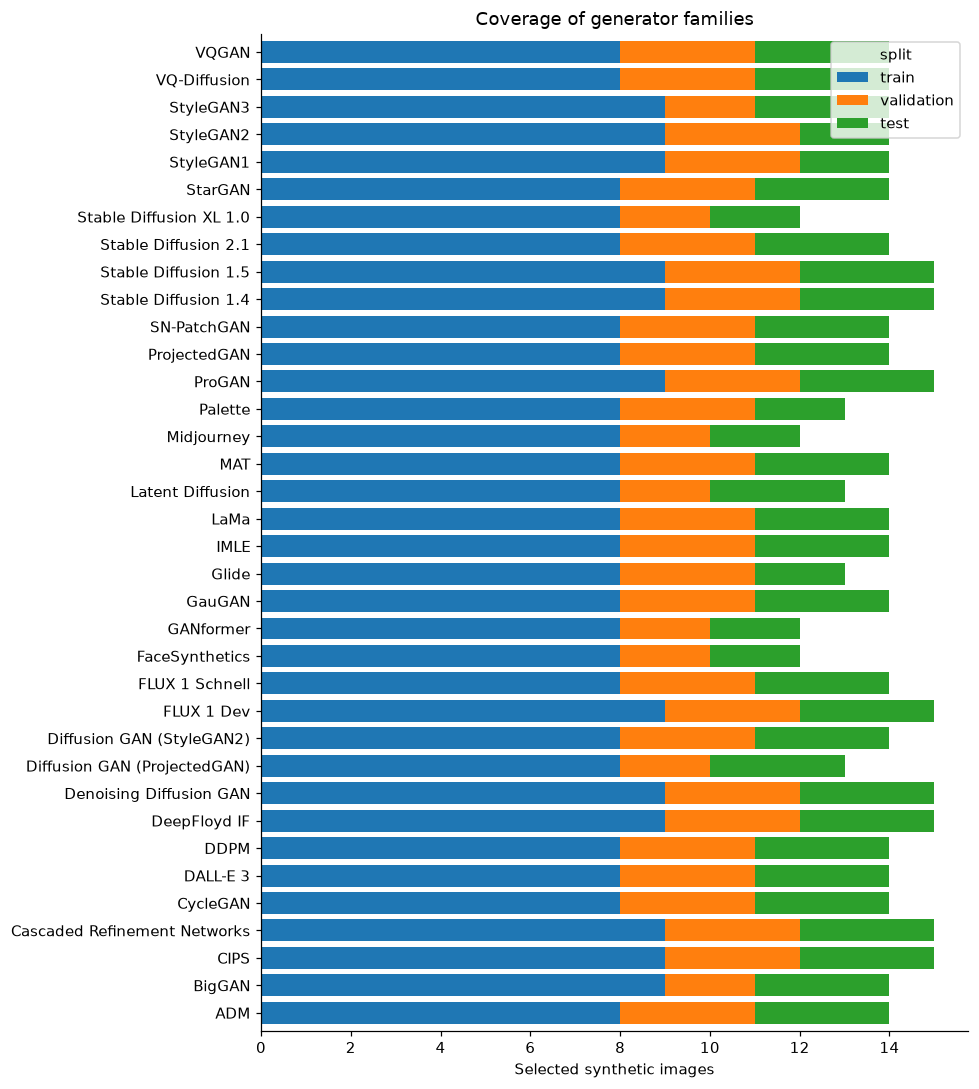

Generators represented: 36


In [3]:
generator_counts = pd.crosstab(selection.loc[selection.label == 1, "generator"], selection["split"])
generator_counts = generator_counts.reindex(columns=["train", "validation", "test"], fill_value=0)
ax = generator_counts.plot.barh(stacked=True, figsize=(9, 10), width=0.8)
ax.set(xlabel="Selected synthetic images", ylabel="", title="Coverage of generator families")
plt.tight_layout()
plt.savefig(RUN_DIR / "generator-coverage.png", bbox_inches="tight")
plt.show()
print(f"Generators represented: {len(generator_counts)}")

## 3. Inspect training examples

The previews below come from the training split. The sample manifest records each
original shard and physical row number, so an exported image remains traceable.

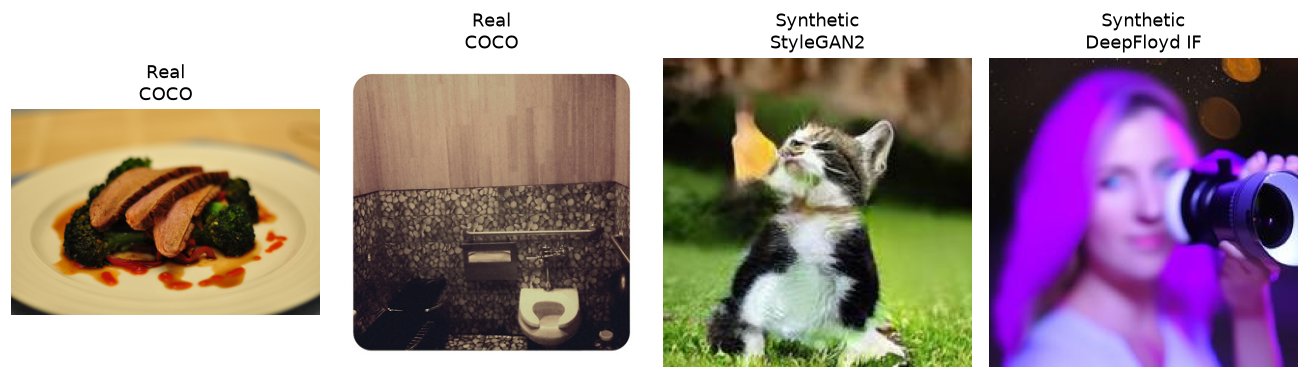

In [4]:
preview_rows = pd.concat(
    [
        selection[(selection.split == "train") & (selection.label == label)].head(2)
        for label in (0, 1)
    ]
)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.5))
for ax, row in zip(axes, preview_rows.itertuples(), strict=True):
    with Image.open(row.path) as opened:
        thumbnail = ImageOps.exif_transpose(opened).convert("RGB")
        thumbnail.thumbnail((320, 320))
        ax.imshow(thumbnail)
    ax.set_title(f"{'Real' if row.label == 0 else 'Synthetic'}\n{row.generator}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Measure all features and inspect fractal dimension

`extract` applies EXIF orientation, transparency handling, grayscale conversion, a
center crop, and resizing. We use the default **128 × 128** image, five box scales,
Gaussian residual, all eight D4 transforms, and range/domain matching.

| Measurement | Meaning |
| --- | --- |
| Gray/residual differential dimension | Roughness of a grayscale surface across box sizes; approximately 2–3 |
| Edge box dimension | How occupied edge boxes scale with box size; approximately 0–2 |
| R² and slope standard error | How well the chosen scales support a straight log–log fit |
| Rényi D0/D1/D2 | Scaling of support, information, and concentration of absolute residual mass |
| Lacunarity | Unevenness of residual mass across boxes |
| Residual standard deviation/entropy | Residual strength and histogram irregularity |
| Spectral similarities | Repetition after shifting the Fourier magnitude spectrum |
| Compression errors/contrasts | How well transformed, reduced domain blocks reproduce range blocks |

These are finite-scale estimates, not exact dimensions of an infinite fractal.
No single dimension or cutoff establishes whether an image is synthetic.

This demonstration explicitly uses 128-pixel analysis to keep comparisons and runtime consistent. Omit `image_size` for automatic sizing from the largest training image; see the [method guide](../docs/method-catalog.md#automatic-image-sizing).

In [5]:
features = FeatureConfig(image_size=128)
example_paths = {
    "real": Path(selection[(selection.split == "train") & (selection.label == 0)].iloc[0].path),
    "synthetic": Path(
        selection[(selection.split == "train") & (selection.label == 1)].iloc[0].path
    ),
}
measurements = {name: extract(path, features) for name, path in example_paths.items()}
display(pd.DataFrame({name: result.features for name, result in measurements.items()}).round(6))
dimension_rows = [
    {
        "image": label,
        "method": name,
        "dimension": value.value,
        "R²": value.r_squared,
        "slope SE": value.slope_standard_error,
        "reason": value.reason,
    }
    for label, result in measurements.items()
    for name, value in result.dimensions.items()
]
display(pd.DataFrame(dimension_rows).round(6))
print("Preprocessing/fit warnings:")
for name, result in measurements.items():
    print(name, list(result.warnings))

,real,synthetic
gray_dimension,2.120853,2.183757
gray_dimension_r2,0.995072,0.994000
residual_dimension,2.196241,2.218521
residual_dimension_r2,0.997774,0.999045
edge_dimension,1.714731,1.632123
edge_dimension_r2,0.999227,0.998815
edge_dimension_valid,1.000000,1.000000
residual_d0,2.000000,2.000000
residual_d1,1.861977,1.874567
residual_d2,1.798107,1.805001


,image,method,dimension,R²,slope SE,reason
0,real,gray,2.120853,0.995072,0.086174,None
1,real,residual,2.196241,0.997774,0.059892,None
2,real,edge,1.714731,0.999227,0.027533,None
3,synthetic,gray,2.183757,0.994000,0.097958,None
4,synthetic,residual,2.218521,0.999045,0.039592,None
5,synthetic,edge,1.632123,0.998815,0.032453,None


Preprocessing/fit warnings:
real ['center crop removed borders to preserve aspect ratio', 'resized from 425 to 128; resizing can alter forensic traces']
synthetic ['resized from 200 to 128; resizing can alter forensic traces']


For the next visualization only, we use the package's internal preprocessing helpers
`load_image` and `noise_residual` to show exactly what `extract` measured. Application
code can use the public `extract` result without these helpers.

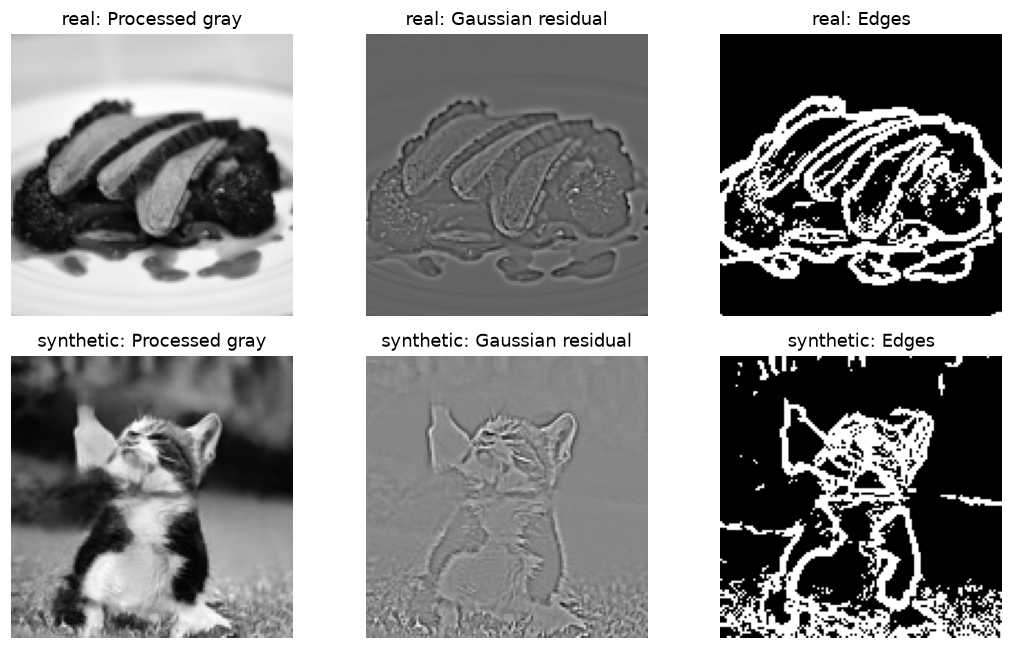

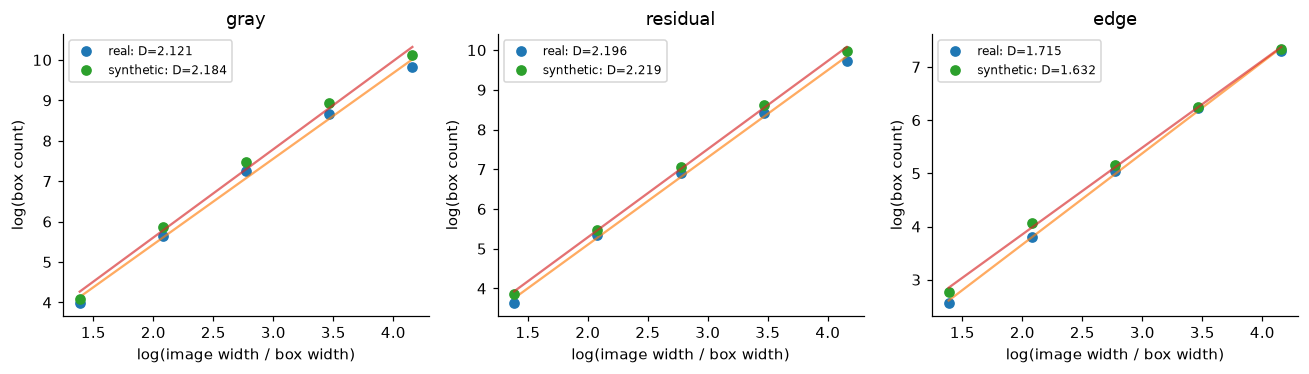

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for row_index, (name, path) in enumerate(example_paths.items()):
    gray, _, _, _ = load_image(path, features)
    residual = noise_residual(gray, features)
    gy, gx = np.gradient(gray)
    edges = np.hypot(gy, gx) > measurements[name].diagnostics["edge_threshold"]
    for ax, values, title in zip(
        axes[row_index],
        (gray, residual, edges),
        ("Processed gray", "Gaussian residual", "Edges"),
        strict=True,
    ):
        ax.imshow(values, cmap="gray")
        ax.set_title(f"{name}: {title}")
        ax.axis("off")
plt.tight_layout()
plt.savefig(RUN_DIR / "preprocessing.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, method in zip(axes, ("gray", "residual", "edge"), strict=True):
    for name, result in measurements.items():
        estimate = result.dimensions[method]
        x = np.log(result.processed_shape[0] / np.array(estimate.scales))
        y = np.log(estimate.counts)
        slope, intercept = np.polyfit(x, y, 1)
        ax.plot(x, y, "o", label=f"{name}: D={estimate.value:.3f}")
        ax.plot(x, slope * x + intercept, alpha=0.65)
    ax.set(xlabel="log(image width / box width)", ylabel="log(box count)", title=method)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RUN_DIR / "dimension-fits.png", bbox_inches="tight")
plt.show()

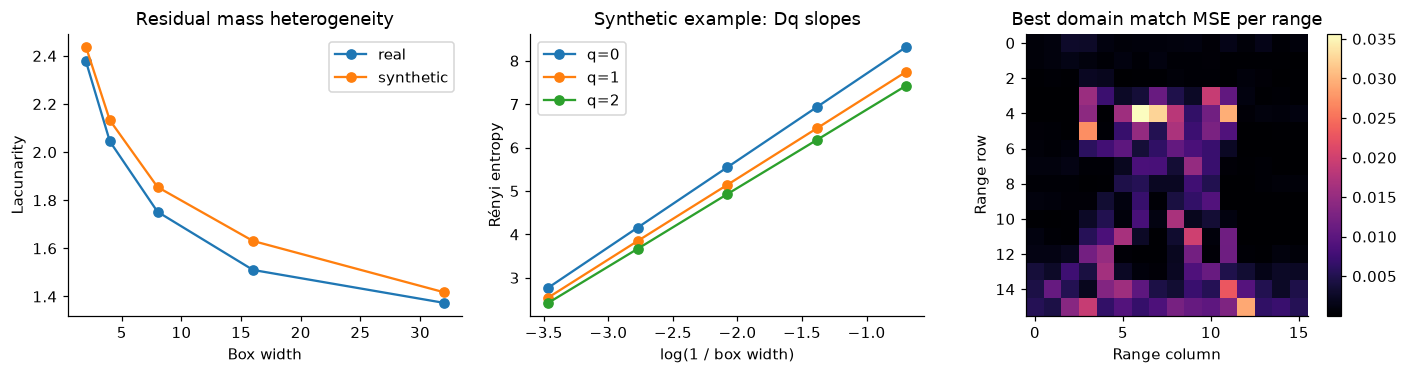

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for name, result in measurements.items():
    axes[0].plot(features.scales, result.diagnostics["lacunarity"], "o-", label=name)
axes[0].set(xlabel="Box width", ylabel="Lacunarity", title="Residual mass heterogeneity")
axes[0].legend()
curves = np.asarray(measurements["synthetic"].diagnostics["renyi_entropy_curves"])
for q in range(3):
    axes[1].plot(-np.log(features.scales), curves[:, q], "o-", label=f"q={q}")
axes[1].set(
    xlabel="log(1 / box width)", ylabel="Rényi entropy", title="Synthetic example: Dq slopes"
)
axes[1].legend()
compression = measurements["synthetic"].diagnostics["compression"]
matches = np.asarray(compression["matches_mse_contrast_offset_domain"])
side = compression["range_grid_side"]
heatmap = axes[2].imshow(matches[:, 0].reshape(side, side), cmap="magma")
axes[2].set(title="Best domain match MSE per range", xlabel="Range column", ylabel="Range row")
fig.colorbar(heatmap, ax=axes[2])
plt.tight_layout()
plt.savefig(RUN_DIR / "mass-and-compression.png", bbox_inches="tight")
plt.show()

## 5. Alternative residuals and optional compression

Gaussian subtraction removes smooth structure. SVD subtraction removes the largest
low-rank components after column centering. Disabling compression omits its five
features and reduces work. Changing any of these feature settings requires retraining
the classifier. The small comparison below is illustrative; it does not select a model
using test outcomes. The main experiment keeps the defaults fixed.

In [8]:
variants = {
    "Gaussian + compression": features,
    "SVD + compression": FeatureConfig(image_size=128, residual="svd", svd_rank=8),
    "Gaussian, no compression": FeatureConfig(image_size=128, compression=False),
}
variant_results = {name: extract(example_paths["real"], cfg) for name, cfg in variants.items()}
display(
    pd.DataFrame(
        [
            {
                "configuration": name,
                "feature count": len(result.features),
                "residual dimension": result.dimensions["residual"].value,
                "residual R²": result.dimensions["residual"].r_squared,
                "seconds": result.elapsed_seconds,
            }
            for name, result in variant_results.items()
        ]
    )
)

,configuration,feature count,residual dimension,residual R²,seconds
0,Gaussian + compression,21,2.196241,0.997774,0.026193
1,SVD + compression,21,2.197396,0.997339,0.035352
2,"Gaussian, no compression",16,2.196241,0.997774,0.015901


## 6. Native C and NumPy fallback

The same Python API supports `backend="auto"`, `"native"`, and `"python"`. The C
extension accelerates box statistics and affine block search. We verify feature
agreement and report a small warm, single-image timing, which is not a general benchmark.
Without a compiled extension, this cell still demonstrates the NumPy implementation.

In [9]:
timings = []
backend_results = {}
for backend in ["python", "native"] if native_available() else ["python"]:
    cfg = FeatureConfig(image_size=128, backend=backend)
    extract(example_paths["real"], cfg)
    durations = []
    for _ in range(3):
        started = perf_counter()
        backend_results[backend] = extract(example_paths["real"], cfg)
        durations.append(perf_counter() - started)
    timings.append({"backend": backend, "median seconds": float(np.median(durations))})
if "native" in backend_results:
    np.testing.assert_allclose(
        list(backend_results["native"].features.values()),
        list(backend_results["python"].features.values()),
        rtol=1e-8,
        atol=1e-10,
    )
display(pd.DataFrame(timings))

,backend,median seconds
0,python,0.044818
1,native,0.026172


## 7. CSV, Parquet, embedded bytes, and the Python data API

Training uses a CSV manifest; validation and test use path-based Parquet manifests.
The first example below also reads an actual Hugging Face image struct from an original
AI-GenBench shard. Only one record is requested. The two-image Parquet file demonstrates
embedding both labels with bytes, and `extract` accepts file paths, encoded bytes, and arrays.

In [10]:
samples = {split: read_manifest(path, require_labels=True) for split, path in manifests.items()}
first_shard = selection.loc[selection.label == 1, "source"].iloc[0]
reader = iter_manifest(first_shard, source=DataSource(paths=(first_shard,), label=1), batch_size=1)
try:
    original_record = next(reader)
finally:
    reader.close()
assert original_record.image_bytes is not None
print(f"Original Parquet record: {original_record.path}")
print(f"Encoded bytes: {len(original_record.image_bytes):,}; label: {original_record.label}")

embedded_path = RUN_DIR / "two-images.parquet"
pq.write_table(
    pa.Table.from_pylist(
        [
            {
                "image": {"bytes": path.read_bytes(), "path": path.name},
                "label": label,
                "group": f"embedded-demo-{label}",
            }
            for label, path in enumerate(example_paths.values())
        ]
    ),
    embedded_path,
)
embedded_samples = list(iter_sources([embedded_path], require_labels=True, batch_size=1))
encoded_result = extract(example_paths["real"].read_bytes(), features)
with Image.open(example_paths["real"]) as opened:
    array_result = extract(np.asarray(ImageOps.exif_transpose(opened).convert("RGB")), features)
assert encoded_result.image_id == array_result.image_id == measurements["real"].image_id
print("Paths, bytes, and the equivalent RGB array identify the same decoded image.")
print(f"Loaded split sizes: { {name: len(rows) for name, rows in samples.items()} }")

Original Parquet record: D:\Pulpit\Fractal-Image-Detector\data\AI-GenBench-fake_part\data\train-00044-of-00057.parquet#row=0
Encoded bytes: 8,277; label: 1
Paths, bytes, and the equivalent RGB array identify the same decoded image.
Loaded split sizes: {'train': 600, 'validation': 200, 'test': 200}


## 8. Train with explicit splits, a TOML file, and MLflow

The scaler and logistic regression fit **only the 600 training images** at the default
sample size. Validation and test each contain 100 real + 100 fake images. There is no
threshold tuning, automatic early stopping, or refitting on held-out data. The fixed
threshold is 0.5. Known groups and exact decoded image IDs are checked for leakage.

We create a local SQLite MLflow store and an experiment with its artifacts under
`outputs/notebook-demo`. **No server is needed to run these cells.** The UI can be started
afterward. This store is independent of any existing `mlflow.db` in the project root.

Edit the generated `train.toml` to change paths, features, workers, or tracking.
Paths in a task file are relative to that file. Equivalent API:

```python
from fractal_detector import train_splits
result = train_splits(samples["train"], samples["validation"], samples["test"],
                      features, TrainingConfig(seed=SEED), workers=WORKERS)
```

We execute the configuration once below; `run_config` calls that same training API.

In [11]:
TRACKING_URI = "sqlite:///" + (OUTPUT_ROOT / "mlflow.db").as_posix()
EXPERIMENT = "coco-aigenbench-notebook"
client = MlflowClient(tracking_uri=TRACKING_URI)
if client.get_experiment_by_name(EXPERIMENT) is None:
    artifact_root = OUTPUT_ROOT / "mlflow-artifacts"
    artifact_root.mkdir(exist_ok=True)
    client.create_experiment(EXPERIMENT, artifact_location=artifact_root.as_uri())

training_file = RUN_DIR / "train.toml"
training_file.write_text(
    f"""task = "train"
output_dir = "training"
workers = {WORKERS}
batch_size = {BATCH_SIZE}

[data]
train = [{json.dumps(manifests["train"])}]
validation = [{json.dumps(manifests["validation"])}]
test = [{json.dumps(manifests["test"])}]

[features]
image_size = 128
scales = [2, 4, 8, 16, 32]
residual = "gaussian"
backend = "auto"
compression = true
block_size = 8
stride = 8
max_domains = 64
transform_ids = [0, 1, 2, 3, 4, 5, 6, 7]

[training]
seed = {SEED}
threshold = 0.5
regularization_c = 1.0

[tracking]
enabled = true
uri = {json.dumps(TRACKING_URI)}
experiment = {json.dumps(EXPERIMENT)}
run_name = "balanced-explicit-training"
image_logging = "full"
""",
    encoding="utf-8",
)
assert load_config(training_file).features == features
print(training_file.read_text(encoding="utf-8"))
started = perf_counter()
training_summary = run_config(training_file)
training_seconds = perf_counter() - started
MODEL_PATH = RUN_DIR / "training/model.json"
detector = Detector.load(MODEL_PATH)
print(f"Training, evaluation, and MLflow logging: {training_seconds:.1f} seconds")
display(pd.DataFrame(training_summary["metrics"]).round(4))

task = "train"
output_dir = "training"
workers = 4
batch_size = 16

[data]
train = ["D:\\Pulpit\\Fractal-Image-Detector\\Fractal-synthetic-image-detector\\outputs\\notebook-demo\\sample-1337-500-9be55ad838ce6753\\train.csv"]
validation = ["D:\\Pulpit\\Fractal-Image-Detector\\Fractal-synthetic-image-detector\\outputs\\notebook-demo\\sample-1337-500-9be55ad838ce6753\\validation.parquet"]
test = ["D:\\Pulpit\\Fractal-Image-Detector\\Fractal-synthetic-image-detector\\outputs\\notebook-demo\\sample-1337-500-9be55ad838ce6753\\test.parquet"]

[features]
image_size = 128
scales = [2, 4, 8, 16, 32]
residual = "gaussian"
backend = "auto"
compression = true
block_size = 8
stride = 8
max_domains = 64
transform_ids = [0, 1, 2, 3, 4, 5, 6, 7]

[training]
seed = 1337
threshold = 0.5
regularization_c = 1.0

[tracking]
enabled = true
uri = "sqlite:///D:/Pulpit/Fractal-Image-Detector/Fractal-synthetic-image-detector/outputs/notebook-demo/mlflow.db"
experiment = "coco-aigenbench-notebook"
run_name = "bal

Training, evaluation, and MLflow logging: 352.1 seconds


,validation,test
accuracy,0.7200,0.7600
balanced_accuracy,0.7200,0.7600
roc_auc,0.8135,0.8151
average_precision,0.7937,0.8028
log_loss,0.6040,0.5312
brier_score,0.1768,0.1771


## 9. Held-out evaluation and feature distributions

Accuracy and balanced accuracy measure decisions at threshold 0.5. ROC AUC measures
ranking over thresholds; average precision summarizes precision/recall. Log loss and
Brier score measure probability error (smaller is better). These are descriptive scores
for this sample. The test results below are inspected after fitting with fixed settings.

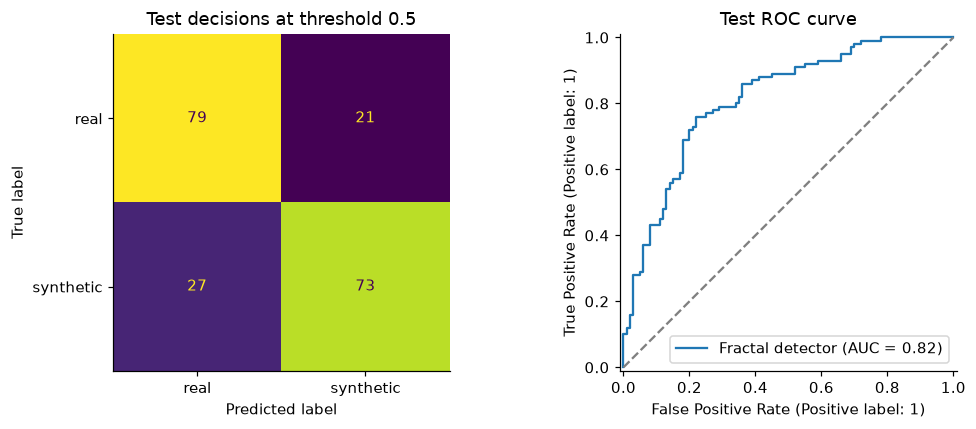

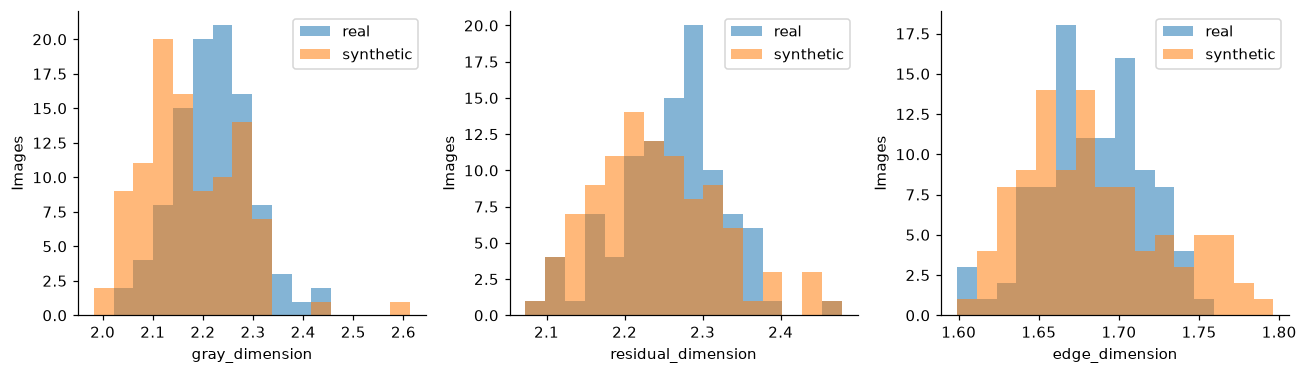

In [12]:
reports = json.loads((RUN_DIR / "training/report.json").read_text(encoding="utf-8"))
cached_features = {
    split: [
        FeatureResult.model_validate_json(line)
        for line in (RUN_DIR / f"training/{split}-features.jsonl")
        .read_text(encoding="utf-8")
        .splitlines()
    ]
    for split in samples
}
ids = {split: {result.image_id for result in rows} for split, rows in cached_features.items()}
assert len(set.union(*ids.values())) == 2 * PER_CLASS
test_report = reports["test"]
y_test = np.array([sample.label for sample in samples["test"]])
probabilities = np.array([p["synthetic_probability"] for p in test_report["predictions"]])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(
    np.asarray(test_report["confusion_matrix"]), display_labels=["real", "synthetic"]
).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Test decisions at threshold 0.5")
RocCurveDisplay.from_predictions(y_test, probabilities, ax=axes[1], name="Fractal detector")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_title("Test ROC curve")
plt.tight_layout()
plt.savefig(RUN_DIR / "test-evaluation.png", bbox_inches="tight")
plt.show()

test_features = pd.DataFrame([r.features for r in cached_features["test"]])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, column in zip(
    axes, ["gray_dimension", "residual_dimension", "edge_dimension"], strict=True
):
    edges = np.histogram_bin_edges(test_features[column], bins=16)
    for label, name in ((0, "real"), (1, "synthetic")):
        ax.hist(test_features.loc[y_test == label, column], bins=edges, alpha=0.55, label=name)
    ax.set(xlabel=column, ylabel="Images")
    ax.legend()
plt.tight_layout()
plt.savefig(RUN_DIR / "test-dimensions.png", bbox_inches="tight")
plt.show()

### 9.1. Real versus synthetic: measured statistics

The next table joins the actual measurements to their image paths, source labels, and
splits. **All-sample plots describe 500 real + 500 synthetic images**; plots marked
**test** use only the 100 real + 100 synthetic held-out images. Training images are
excluded from the reported detection scores and example galleries.

Undefined dimensions are shown as missing in these descriptive tables and plots.
The model's stored feature convention remains unchanged. Each point in a distribution
plot is one measured image; boxes show the median and middle 50% of values, with
whiskers extending to the usual 1.5× interquartile-range limit.

In [13]:
CLASS_NAMES = {0: "Real", 1: "Synthetic"}
CLASS_COLORS = {"Real": "#28799b", "Synthetic": "#c25b32"}
class_order = ["Real", "Synthetic"]
stat_rows = []
for split, split_samples in samples.items():
    for index, (sample, measured) in enumerate(
        zip(split_samples, cached_features[split], strict=True)
    ):
        assert sample.path == measured.source
        height, width = measured.original_shape
        row = {
            "path": sample.path,
            "split": split,
            "sample_index": index,
            "class": CLASS_NAMES[sample.label],
            "image_id": measured.image_id,
            "height": height,
            "width": width,
            "megapixels": height * width / 1e6,
            "encoded_kib": Path(sample.path).stat().st_size / 1024,
            "warning_count": len(measured.warnings),
            "extraction_seconds": measured.elapsed_seconds,
            **measured.features,
        }
        for name, estimate in measured.dimensions.items():
            row[f"{name}_dimension"] = estimate.value
            row[f"{name}_dimension_r2"] = estimate.r_squared
            row[f"{name}_dimension_se"] = estimate.slope_standard_error
        stat_rows.append(row)
image_stats = pd.DataFrame(stat_rows).merge(
    selection[["path", "generator", "source", "row"]].rename(columns={"row": "source_row"}),
    on="path",
    how="left",
    validate="one_to_one",
)
assert len(image_stats) == 2 * PER_CLASS and image_stats.generator.notna().all()
test_stats = image_stats[image_stats.split == "test"].copy().set_index("sample_index").sort_index()
assert test_stats["path"].tolist() == [sample.path for sample in samples["test"]]
test_stats["synthetic_probability"] = probabilities
test_stats["predicted_class"] = np.where(
    probabilities >= detector.artifact.threshold, "Synthetic", "Real"
)
test_stats["correct"] = test_stats["class"] == test_stats["predicted_class"]
image_stats.to_csv(RUN_DIR / "image-statistics.csv", index=False)
test_stats.to_csv(RUN_DIR / "test-image-statistics.csv", index=True)

important_stats = {
    "gray_dimension": "Gray surface dimension",
    "residual_dimension": "Residual surface dimension",
    "edge_dimension": "Edge box dimension",
    "residual_d1": "Residual information dimension D1",
    "lacunarity_mean": "Mean lacunarity",
    "residual_entropy": "Residual entropy (bits)",
    "residual_std": "Residual standard deviation",
    "compression_mse_mean": "Mean range/domain match MSE",
    "spectrum_similarity_half": "Half-shift spectral similarity",
}
class_summary = (
    image_stats.melt(id_vars=["class"], value_vars=list(important_stats), var_name="statistic")
    .groupby(["statistic", "class"], sort=False)["value"]
    .agg(
        n="count",
        mean="mean",
        std="std",
        median="median",
        q25=lambda values: values.quantile(0.25),
        q75=lambda values: values.quantile(0.75),
    )
)
class_summary.to_csv(RUN_DIR / "class-statistics.csv")
print(f"Descriptive statistics for all {len(image_stats)} sampled images (all splits):")
display(class_summary.round(5))
print("Held-out decisions only:")
display(
    test_stats.groupby("class")
    .agg(
        images=("correct", "size"),
        correct=("correct", "sum"),
        class_recall=("correct", "mean"),
        mean_synthetic_probability=("synthetic_probability", "mean"),
    )
    .round(4)
)

Descriptive statistics for all 1000 sampled images (all splits):


n     mean      std   median      q25  \
statistic                class                                                
gray_dimension           Real       500  2.22176  0.08253  2.21692  2.17114   
                         Synthetic  500  2.17197  0.09875  2.15367  2.10060   
residual_dimension       Real       500  2.25987  0.07425  2.25862  2.20938   
                         Synthetic  500  2.23515  0.08772  2.22658  2.17368   
edge_dimension           Real       500  1.68607  0.03917  1.68397  1.65925   
                         Synthetic  500  1.67747  0.04491  1.67426  1.64737   
residual_d1              Real       500  1.86233  0.05058  1.86784  1.83052   
                         Synthetic  500  1.85353  0.05829  1.86087  1.82233   
lacunarity_mean          Real       500  1.74002  0.80271  1.61751  1.42385   
                         Synthetic  500  1.82987  0.57089  1.70890  1.45467   
residual_entropy         Real       500  3.68205  0.53145  3.72429  3.36351   
                         Synthetic  500  3.55547  0.59287  3.55654  3.15245   
residual_std             Real       500  0.04862  0.01551  0.04767  0.03827   
                         Synthetic  500  0.03861  0.01850  0.03518  0.02604   
compression_mse_mean     Real       500  0.00540  0.00329  0.00475  0.00325   
                         Synthetic  500  0.00399  0.00438  0.00289  0.00177   
spectrum_similarity_half Real       500  0.00317  0.03070  0.00464 -0.01633   
                         Synthetic  500  0.01770  0.02855  0.01733  0.00207   

                                        q75  
statistic                class               
gray_dimension           Real       2.26971  
                         Synthetic  2.23407  
residual_dimension       Real       2.30916  
                         Synthetic  2.29114  
edge_dimension           Real       1.71136  
                         Synthetic  1.70516  
residual_d1              Real       1.90125  
                         Synthetic  1.89138  
lacunarity_mean          Real       1.86641  
                         Synthetic  2.03411  
residual_entropy         Real       4.07148  
                         Synthetic  3.95356  
residual_std             Real       0.05715  
                         Synthetic  0.04645  
compression_mse_mean     Real       0.00680  
                         Synthetic  0.00496  
spectrum_similarity_half Real       0.02136  
                         Synthetic  0.03347

Held-out decisions only:


,images,correct,class_recall,mean_synthetic_probability
class,,,,
Real,100,79,0.79,0.3542
Synthetic,100,73,0.73,0.6462


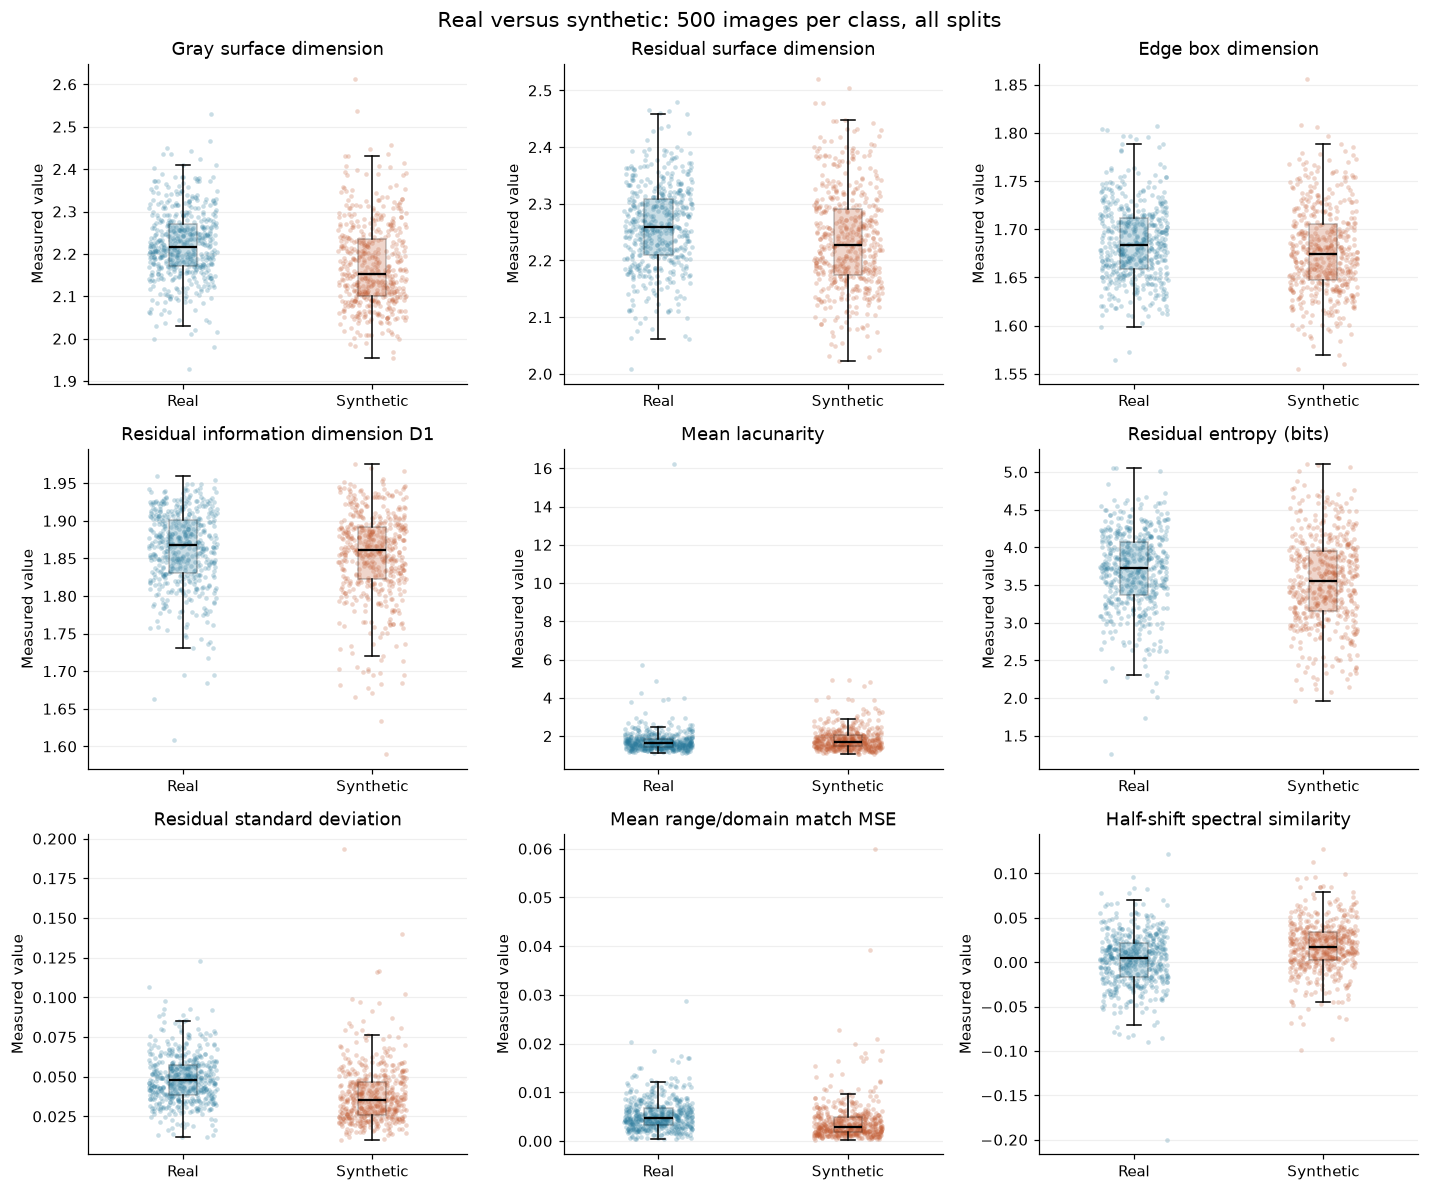

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(13, 11))
jitter_rng = np.random.default_rng(SEED)
for ax, (column, title) in zip(axes.flat, important_stats.items(), strict=True):
    values_by_class = [
        image_stats.loc[image_stats["class"] == name, column].dropna().to_numpy()
        for name in class_order
    ]
    boxes = ax.boxplot(
        values_by_class,
        tick_labels=class_order,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "black", "linewidth": 1.5},
    )
    for position, (name, values, patch) in enumerate(
        zip(class_order, values_by_class, boxes["boxes"], strict=True), start=1
    ):
        patch.set_facecolor(CLASS_COLORS[name])
        patch.set_alpha(0.25)
        ax.scatter(
            position + jitter_rng.uniform(-0.18, 0.18, len(values)),
            values,
            s=9,
            alpha=0.25,
            color=CLASS_COLORS[name],
            linewidths=0,
        )
    ax.set(title=title, ylabel="Measured value")
    ax.grid(axis="y", alpha=0.2)
fig.suptitle(f"Real versus synthetic: {PER_CLASS} images per class, all splits", fontsize=14)
plt.tight_layout()
plt.savefig(RUN_DIR / "class-feature-distributions.png", bbox_inches="tight")
plt.show()

### 9.2. Fit quality and source-image statistics

Dimension is the fitted log–log slope, so inspect **R² and slope standard error** as
well as its value. Low R² means the five measured scales do not closely follow a
single power law. The slope error describes this fit; it is not a confidence estimate
for synthetic-image detection.

Original pixel count and file size are **descriptive metadata, not classifier inputs**.
Their differences help reveal source/encoding effects. The detector measures resized
128 × 128 images, but that does not remove all traces of the original source.

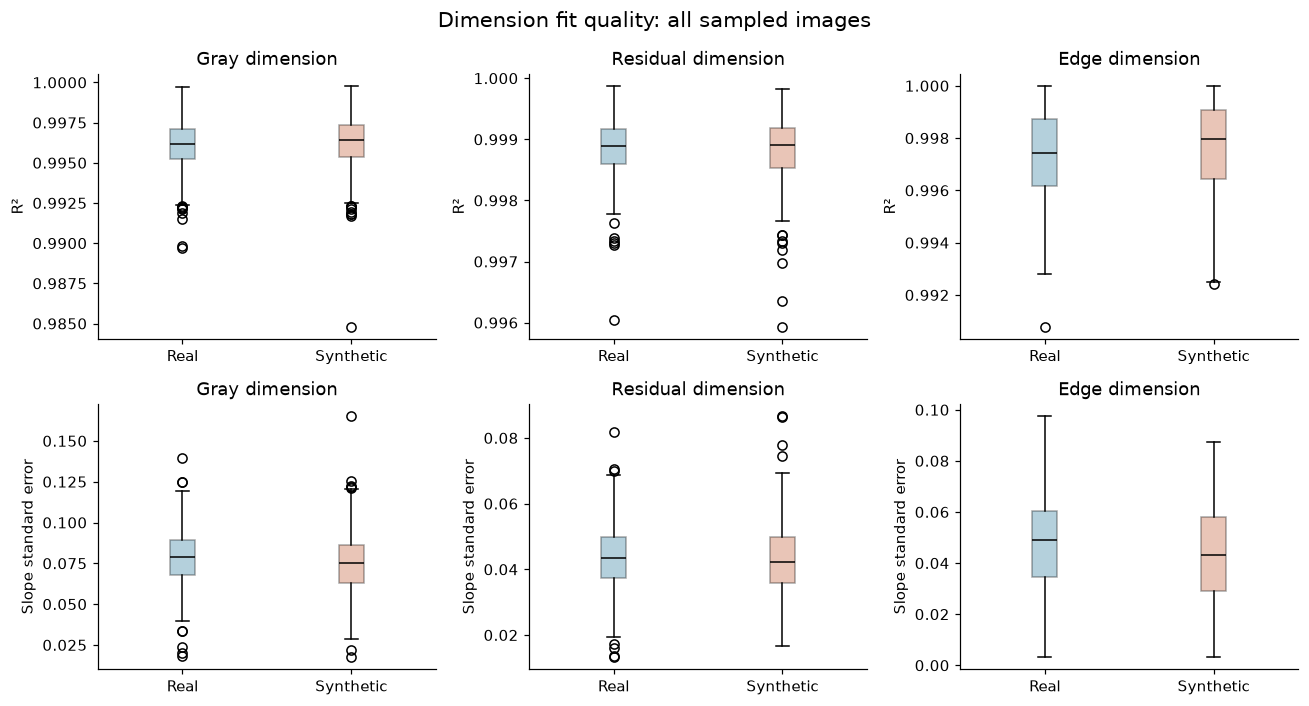

,class,dimension,valid,undefined,R² below 0.95,median R²,median slope SE
0,Real,gray,500,0,0,0.99617,0.07917
1,Synthetic,gray,500,0,0,0.99639,0.07515
2,Real,residual,500,0,0,0.99888,0.04350
3,Synthetic,residual,500,0,0,0.99892,0.04234
4,Real,edge,500,0,0,0.99744,0.04889
5,Synthetic,edge,500,0,0,0.99798,0.04324


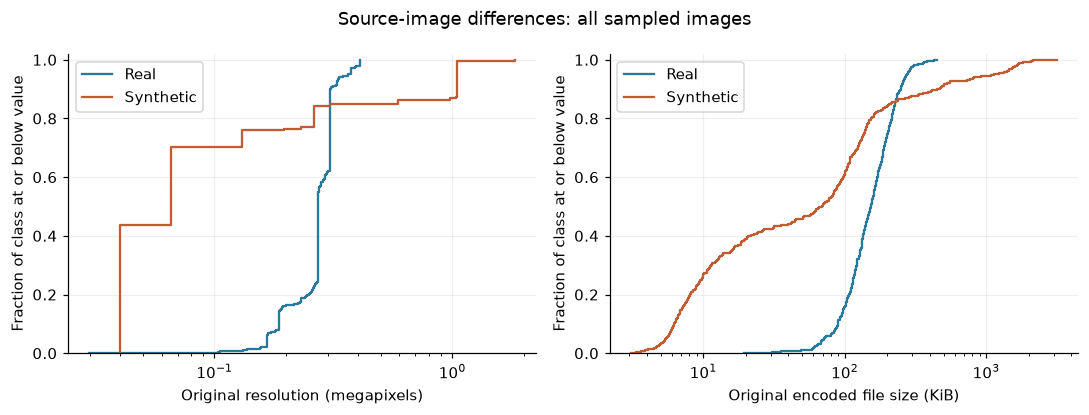

In [15]:
fit_rows = []
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for column_index, name in enumerate(("gray", "residual", "edge")):
    for row_index, (suffix, axis_label) in enumerate(
        (("r2", "R²"), ("se", "Slope standard error"))
    ):
        column = f"{name}_dimension_{suffix}"
        values = [
            image_stats.loc[image_stats["class"] == label, column].dropna() for label in class_order
        ]
        boxes = axes[row_index, column_index].boxplot(
            values, tick_labels=class_order, patch_artist=True, medianprops={"color": "black"}
        )
        for label, patch in zip(class_order, boxes["boxes"], strict=True):
            patch.set_facecolor(CLASS_COLORS[label])
            patch.set_alpha(0.35)
        axes[row_index, column_index].set(title=f"{name.title()} dimension", ylabel=axis_label)
    for label in class_order:
        group = image_stats[image_stats["class"] == label]
        fit_rows.append(
            {
                "class": label,
                "dimension": name,
                "valid": int(group[f"{name}_dimension"].notna().sum()),
                "undefined": int(group[f"{name}_dimension"].isna().sum()),
                "R² below 0.95": int((group[f"{name}_dimension_r2"] < 0.95).sum()),
                "median R²": group[f"{name}_dimension_r2"].median(),
                "median slope SE": group[f"{name}_dimension_se"].median(),
            }
        )
fig.suptitle("Dimension fit quality: all sampled images", fontsize=14)
plt.tight_layout()
plt.savefig(RUN_DIR / "dimension-fit-quality.png", bbox_inches="tight")
plt.show()
fit_summary = pd.DataFrame(fit_rows)
fit_summary.to_csv(RUN_DIR / "dimension-fit-quality.csv", index=False)
display(fit_summary.round(5))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, column, title in zip(
    axes,
    ("megapixels", "encoded_kib"),
    ("Original resolution (megapixels)", "Original encoded file size (KiB)"),
    strict=True,
):
    for label in class_order:
        values = np.sort(image_stats.loc[image_stats["class"] == label, column].to_numpy())
        ax.step(
            values,
            np.arange(1, len(values) + 1) / len(values),
            where="post",
            label=label,
            color=CLASS_COLORS[label],
        )
    ax.set(xlabel=title, ylabel="Fraction of class at or below value", xscale="log", ylim=(0, 1.02))
    ax.legend()
    ax.grid(alpha=0.2)
fig.suptitle("Source-image differences: all sampled images")
plt.tight_layout()
plt.savefig(RUN_DIR / "source-image-statistics.png", bbox_inches="tight")
plt.show()

### 9.3. Examples from both classes, with their actual predictions

Four test images per class are selected with a fixed seed, **without looking at whether
the prediction was correct**. Each panel shows the ground-truth source label, predicted
class, synthetic probability, and gray/residual/edge fractal dimensions. The table adds
fit quality and texture statistics; the matching path and provenance are saved in CSV.
Displayed color thumbnails show the original images, while the dimensions describe
the package's processed grayscale images. Ground truth comes from dataset provenance.

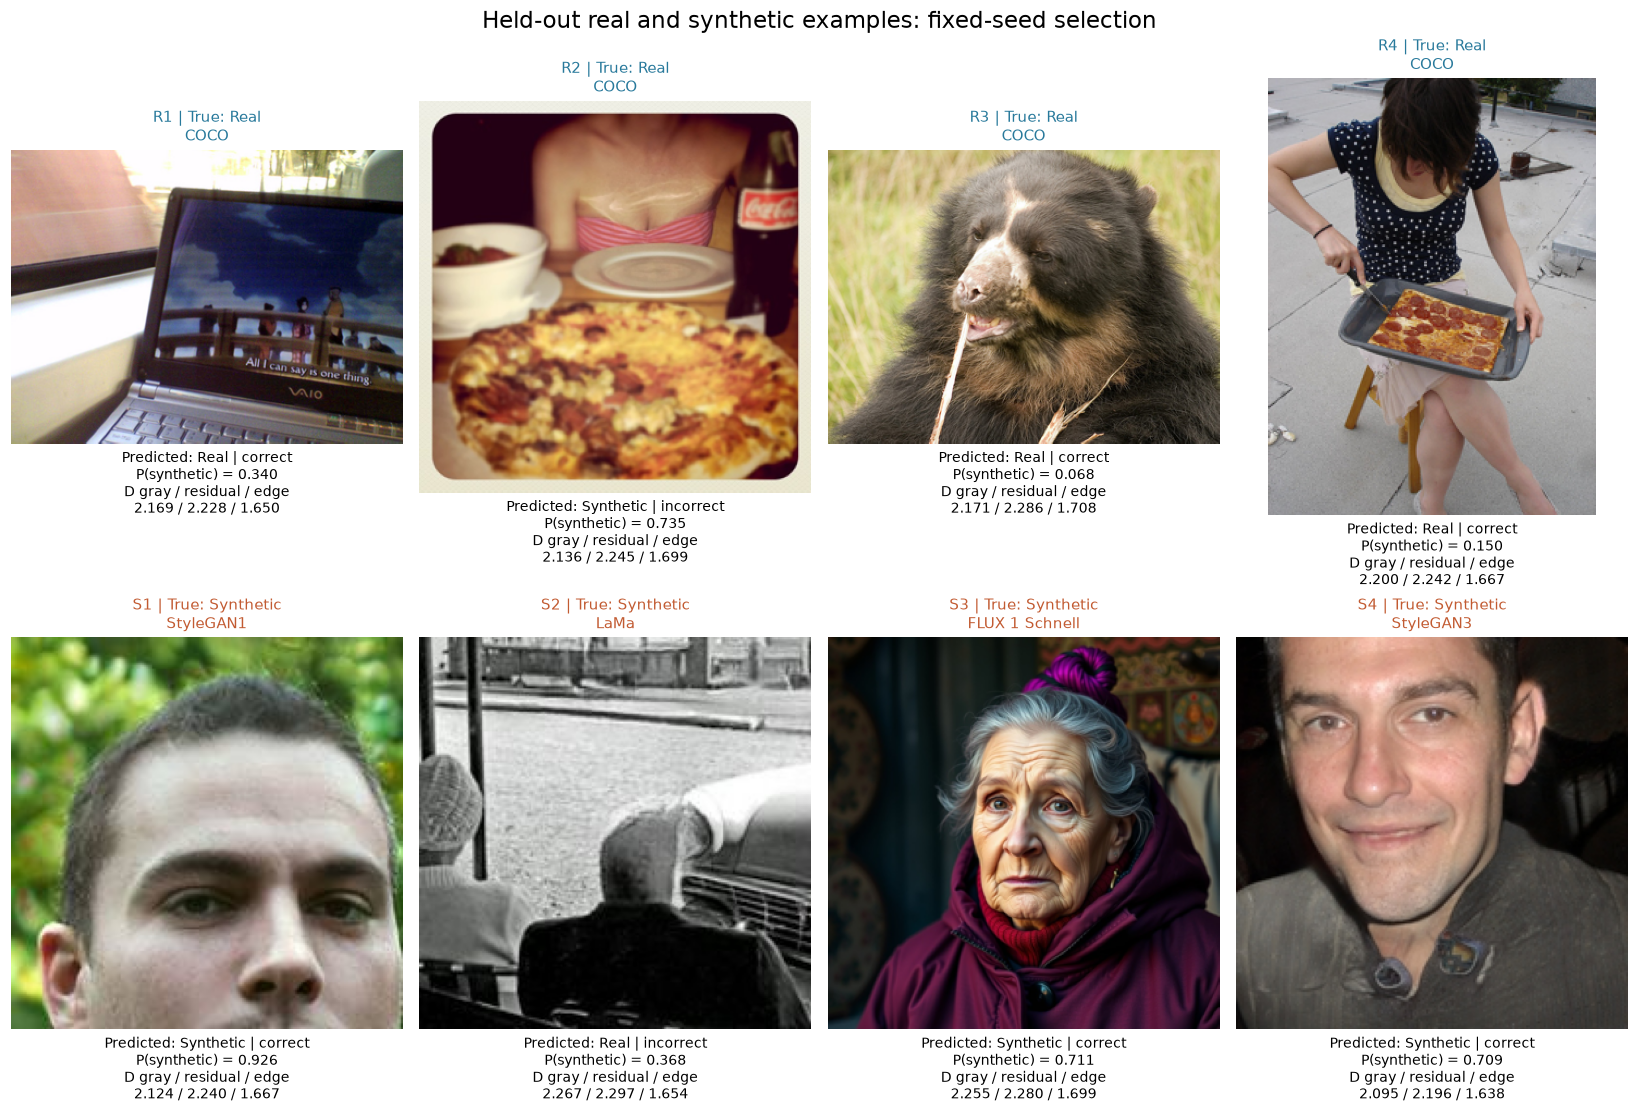

,class,generator,predicted_class,synthetic_probability,correct,gray_dimension,residual_dimension,edge_dimension,residual_dimension_r2,residual_entropy,lacunarity_mean,compression_mse_mean
example,,,,,,,,,,,,
R1,Real,COCO,Real,0.34022,True,2.16894,2.22782,1.64955,0.99841,3.69165,1.74348,0.00293
R2,Real,COCO,Synthetic,0.73491,False,2.13588,2.24486,1.69944,0.99605,4.25450,1.45357,0.00888
R3,Real,COCO,Real,0.06835,True,2.17095,2.28637,1.70805,0.99930,3.49805,1.52086,0.00349
R4,Real,COCO,Real,0.15031,True,2.20013,2.24171,1.66742,0.99905,3.46783,1.77300,0.00439
S1,Synthetic,StyleGAN1,Synthetic,0.92629,True,2.12391,2.24029,1.66682,0.99860,3.72101,1.40012,0.00204
S2,Synthetic,LaMa,Real,0.36845,False,2.26658,2.29679,1.65370,0.99879,4.18059,1.60761,0.00719
S3,Synthetic,FLUX 1 Schnell,Synthetic,0.71125,True,2.25473,2.28033,1.69897,0.99837,3.81974,1.67616,0.00271
S4,Synthetic,StyleGAN3,Synthetic,0.70856,True,2.09474,2.19597,1.63822,0.99923,3.52839,1.69980,0.00161


In [16]:
example_rng = np.random.default_rng(SEED)
gallery_indices = {
    name: sorted(
        example_rng.choice(
            test_stats.index[test_stats["class"] == name].to_numpy(),
            size=min(4, int((test_stats["class"] == name).sum())),
            replace=False,
        ).tolist()
    )
    for name in class_order
}


def draw_prediction_example(ax, index, example_id):
    row = test_stats.loc[index]
    with Image.open(row["path"]) as opened:
        thumbnail = ImageOps.exif_transpose(opened).convert("RGB")
        thumbnail.thumbnail((360, 300))
        ax.imshow(thumbnail)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(
        f"{example_id} | True: {row['class']}\n{row['generator']}",
        fontsize=10,
        color=CLASS_COLORS[row["class"]],
    )
    dimensions = [
        "undefined" if pd.isna(row[f"{name}_dimension"]) else f"{row[f'{name}_dimension']:.3f}"
        for name in ("gray", "residual", "edge")
    ]
    ax.set_xlabel(
        f"Predicted: {row['predicted_class']} | {'correct' if row['correct'] else 'incorrect'}\n"
        f"P(synthetic) = {row['synthetic_probability']:.3f}\n"
        f"D gray / residual / edge\n{' / '.join(dimensions)}",
        fontsize=9,
    )


fig, axes = plt.subplots(2, 4, figsize=(15, 10))
gallery_records = []
for row_index, name in enumerate(class_order):
    for column_index, ax in enumerate(axes[row_index]):
        if column_index >= len(gallery_indices[name]):
            ax.axis("off")
            continue
        index = gallery_indices[name][column_index]
        example_id = f"{name[0]}{column_index + 1}"
        draw_prediction_example(ax, index, example_id)
        gallery_records.append({"example": example_id, **test_stats.loc[index].to_dict()})
fig.suptitle("Held-out real and synthetic examples: fixed-seed selection", fontsize=15)
plt.tight_layout(h_pad=3)
plt.savefig(RUN_DIR / "real-synthetic-examples.png", bbox_inches="tight")
plt.show()
gallery_table = pd.DataFrame(gallery_records)
gallery_table.to_csv(RUN_DIR / "example-statistics.csv", index=False)
display(
    gallery_table.set_index("example")[
        [
            "class",
            "generator",
            "predicted_class",
            "synthetic_probability",
            "correct",
            "gray_dimension",
            "residual_dimension",
            "edge_dimension",
            "residual_dimension_r2",
            "residual_entropy",
            "lacunarity_mean",
            "compression_mse_mean",
        ]
    ].round(5)
)

### 9.4. Inspect mistakes and class overlap

Below are the first two false positives (real predicted synthetic) and first two false
negatives (synthetic predicted real) in test-manifest order, when available. Looking
at errors alongside ordinary examples prevents an overly favorable view of detection.
The probability histogram uses the fixed 0.5 threshold. The scatter plot shows why
two fractal dimensions alone do not separate the classes reliably; the model uses
all 21 features. Test outcomes are displayed after fitting and are not used for tuning.

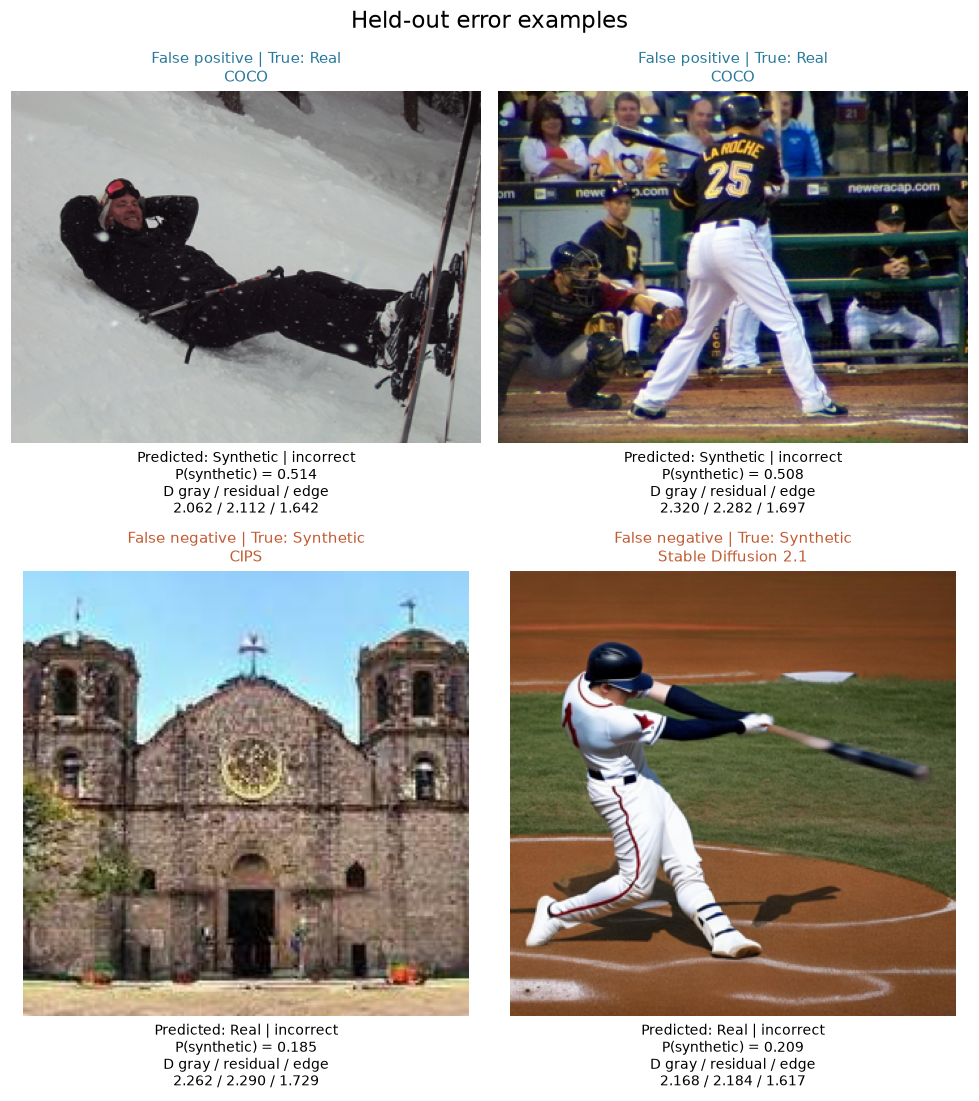

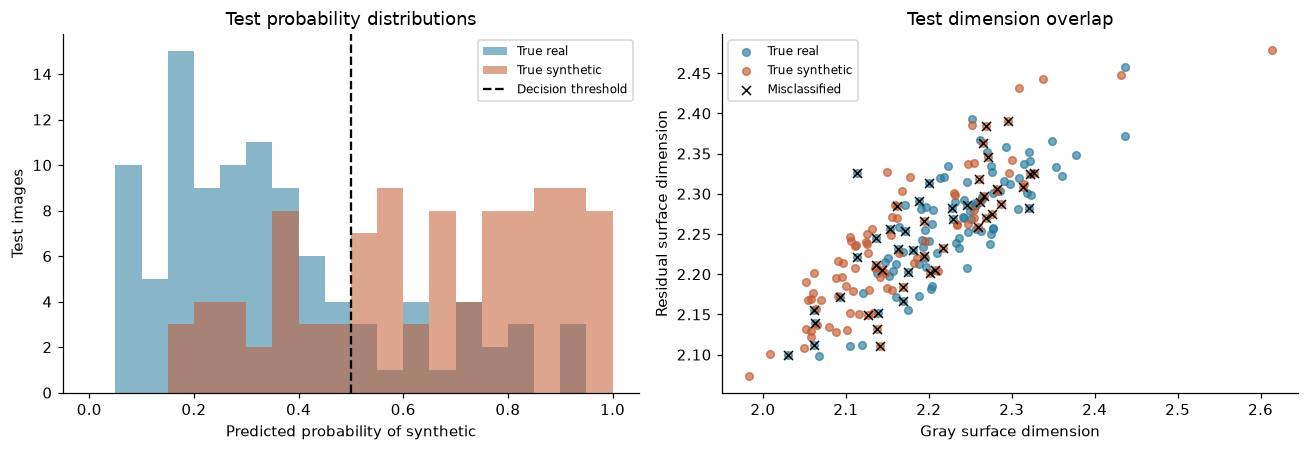

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(9, 10))
error_records = []
for row_index, (name, error_name) in enumerate(
    (("Real", "False positive"), ("Synthetic", "False negative"))
):
    indices = test_stats.index[(test_stats["class"] == name) & ~test_stats["correct"]].tolist()[:2]
    for column_index, ax in enumerate(axes[row_index]):
        if column_index >= len(indices):
            ax.text(
                0.5,
                0.5,
                f"No further {error_name.lower()} in this test set",
                ha="center",
                wrap=True,
            )
            ax.axis("off")
            continue
        index = indices[column_index]
        draw_prediction_example(ax, index, error_name)
        error_records.append({"error_type": error_name, **test_stats.loc[index].to_dict()})
fig.suptitle("Held-out error examples", fontsize=15)
plt.tight_layout(h_pad=3)
plt.savefig(RUN_DIR / "prediction-error-examples.png", bbox_inches="tight")
plt.show()
pd.DataFrame(error_records, columns=["error_type", *test_stats.columns]).to_csv(
    RUN_DIR / "error-example-statistics.csv",
    index=False,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for label in class_order:
    group = test_stats[test_stats["class"] == label]
    axes[0].hist(
        group.synthetic_probability,
        bins=np.linspace(0, 1, 21),
        alpha=0.55,
        label=f"True {label.lower()}",
        color=CLASS_COLORS[label],
    )
    axes[1].scatter(
        group.gray_dimension,
        group.residual_dimension,
        s=25,
        alpha=0.65,
        label=f"True {label.lower()}",
        color=CLASS_COLORS[label],
    )
wrong = test_stats[~test_stats.correct]
axes[0].axvline(
    detector.artifact.threshold, linestyle="--", color="black", label="Decision threshold"
)
axes[0].set(
    xlabel="Predicted probability of synthetic",
    ylabel="Test images",
    title="Test probability distributions",
)
axes[1].scatter(
    wrong.gray_dimension,
    wrong.residual_dimension,
    marker="x",
    s=35,
    linewidths=1,
    color="black",
    label="Misclassified",
)
axes[1].set(
    xlabel="Gray surface dimension",
    ylabel="Residual surface dimension",
    title="Test dimension overlap",
)
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RUN_DIR / "test-probability-and-dimension-overlap.png", bbox_inches="tight")
plt.show()

## 10. Explain a prediction and reload the JSON model

The model standardizes each feature using training means/scales, multiplies by its
learned coefficient, and sums those **log-odds contributions** with an intercept.
The logistic function turns that score into the synthetic probability. Positive
contributions push toward synthetic; negative ones push toward real. This exactly
explains the model's calculation, without establishing a causal forensic explanation.

R1: Classified as real at threshold 0.500. Grayscale surface fractal dimension: 2.1689. Largest log-odds contributions: compression_mse_std +0.630; spectrum_similarity_half -0.560; compression_mse_mean -0.521. Positive terms favor synthetic. This is a learned statistical estimate, not proof of image provenance; probabilities are not independently calibrated.
S1: Classified as synthetic at threshold 0.500. Grayscale surface fractal dimension: 2.1239. Largest log-odds contributions: spectrum_similarity_quarter +2.372; compression_mse_std +0.987; compression_mse_mean -0.777. Positive terms favor synthetic. This is a learned statistical estimate, not proof of image provenance; probabilities are not independently calibrated.


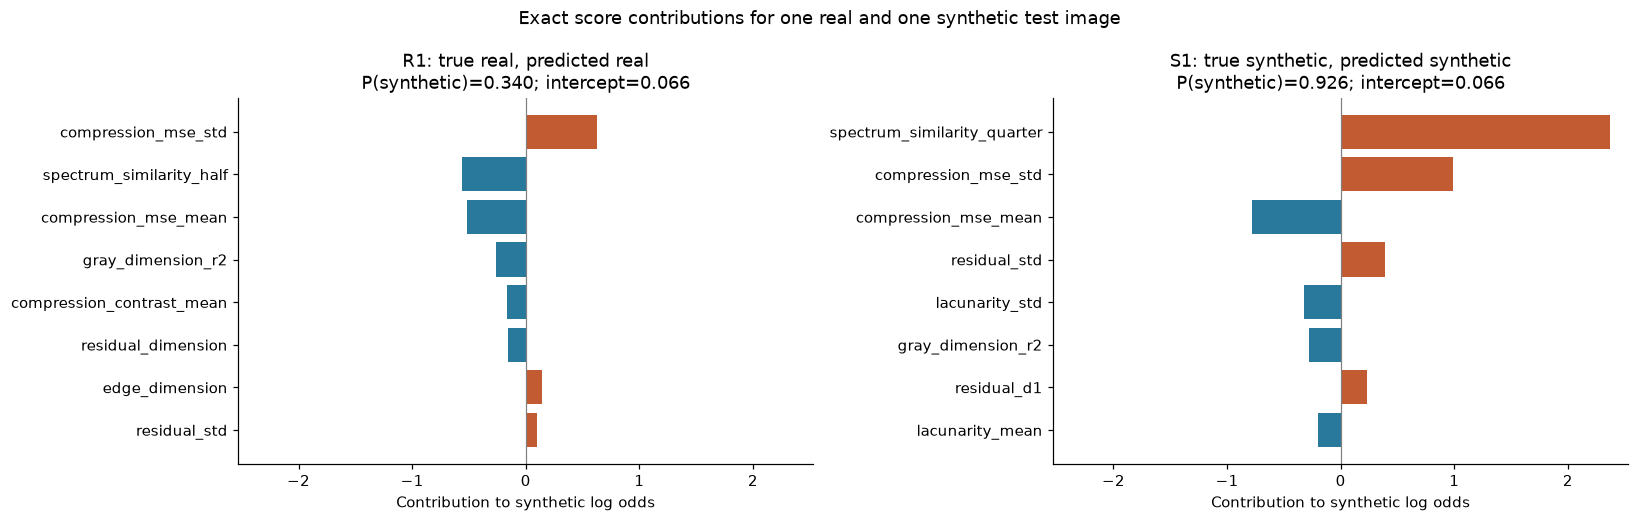

,true_class,sample_index,feature,value,standardized_value,log_odds
0,Real,18,compression_mse_std,0.00373,-0.69044,0.63006
1,Real,18,spectrum_similarity_half,-0.02767,-1.24331,-0.56047
2,Real,18,compression_mse_mean,0.00293,-0.49436,-0.52118
3,Real,18,gray_dimension_r2,0.99459,-1.08099,-0.26185
4,Real,18,compression_contrast_mean,0.41947,-1.15027,-0.16905
5,Real,18,residual_dimension,2.22782,-0.23370,-0.15884
6,Real,18,edge_dimension,1.64955,-0.74628,0.14217
7,Real,18,residual_std,0.03907,-0.27451,0.09766
8,Real,18,compression_mse_p90,0.00788,-0.51786,0.09599
9,Real,18,residual_d1,1.83942,-0.31749,-0.07476


JSON save/load preserves the prediction and preprocessing settings.


In [18]:
explained_predictions = []
explanation_rows = []
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, name in zip(axes, class_order, strict=True):
    index = gallery_indices[name][0]
    case = detector.predict_features(cached_features["test"][index])
    reconstructed = float(expit(case.intercept + sum(c.log_odds for c in case.contributions)))
    assert np.isclose(reconstructed, case.synthetic_probability)
    explained_predictions.append(case)
    contributions = pd.DataFrame([c.model_dump() for c in case.contributions])
    explanation_rows.extend(
        {"true_class": name, "sample_index": index, **row}
        for row in contributions.to_dict(orient="records")
    )
    top = contributions.head(8).iloc[::-1]
    ax.barh(top.feature, top.log_odds, color=np.where(top.log_odds >= 0, "#c25b32", "#28799b"))
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set(
        xlabel="Contribution to synthetic log odds",
        title=f"{name[0]}1: true {name.lower()}, predicted {case.label}\n"
        f"P(synthetic)={case.synthetic_probability:.3f}; intercept={case.intercept:.3f}",
    )
    print(f"{name[0]}1: {case.explanation}")
limit = max(max(abs(value) for value in ax.get_xlim()) for ax in axes)
for ax in axes:
    ax.set_xlim(-limit, limit)
fig.suptitle("Exact score contributions for one real and one synthetic test image")
plt.tight_layout()
plt.savefig(RUN_DIR / "prediction-explanation.png", bbox_inches="tight")
plt.show()
contribution_table = pd.DataFrame(explanation_rows)
contribution_table.to_csv(RUN_DIR / "example-feature-contributions.csv", index=False)
display(contribution_table.round(5))

example_index = gallery_indices["Synthetic"][0]
prediction = explained_predictions[1]
detector.save(RUN_DIR / "model-copy.json")
reloaded = Detector.load(RUN_DIR / "model-copy.json")
repeated = reloaded.predict(samples["test"][example_index].path)
assert np.isclose(repeated.synthetic_probability, prediction.synthetic_probability)
print("JSON save/load preserves the prediction and preprocessing settings.")

## 11. Reuse measured features and try automatic holdout

`fit_features` and `evaluate_features` avoid decoding and measuring the same images
again. Here they reproduce the main fit using its cached training features. For data
without explicit splits, `train` provides a stratified or group-disjoint holdout.
We demonstrate that alternative on 40 training images with compression disabled;
its holdout belongs entirely to the main training split and is not another test score.

In [19]:
cached_detector = fit_features(
    samples["train"], cached_features["train"], features, TrainingConfig(seed=SEED)
)
np.testing.assert_allclose(cached_detector.artifact.coefficients, detector.artifact.coefficients)
cached_evaluation = evaluate_features(cached_detector, samples["test"], cached_features["test"])
assert cached_evaluation.metrics == test_report["metrics"]

small_training = [
    sample for label in (0, 1) for sample in [s for s in samples["train"] if s.label == label][:20]
]
automatic = train(
    small_training,
    FeatureConfig(image_size=64, compression=False),
    TrainingConfig(seed=SEED),
    workers=WORKERS,
)
print("Cached fit reproduced test metrics; no image extraction was repeated.")
print(
    f"Automatic holdout example: {len(automatic.train_indices)} fit / {len(automatic.test_indices)} holdout"
)

Cached fit reproduced test metrics; no image extraction was repeated.
Automatic holdout example: 30 fit / 10 holdout


## 12. Multiple nested directories, bounded prediction, and the CLI

The Python iterator below predicts the two embedded records. The larger task scans
the 200 test images recursively and intentionally lists an overlapping directory to
demonstrate path deduplication. We add **one deliberately invalid file in the output
area** to demonstrate `on_error="skip"`; it is not part of the balanced dataset.

The CLI reads a JSON task. Prediction uses the saved model's preprocessing. Batches
bound retained predictions; worker threads process images within each batch. JSONL
results are written incrementally, and MLflow stores complete per-image records in
batch artifacts. The 200 valid inputs remain exactly 1:1.

In [20]:
api_predictions = list(detector.predict_sources([embedded_path], batch_size=1, workers=WORKERS))
assert len(api_predictions) == 2 and not any(isinstance(p, ImageFailure) for p in api_predictions)
display(
    pd.DataFrame(
        [
            {
                "source": p.measurement.source,
                "label": p.label,
                "probability": p.synthetic_probability,
            }
            for p in api_predictions
        ]
    )
)

broken = RUN_DIR / "invalid-example.jpg"
broken.write_bytes(b"Deliberately invalid input for the error-handling demonstration.")
prediction_config = TaskConfig(
    task="predict",
    inputs=(str(SAMPLE_DIR / "images/test"), str(SAMPLE_DIR / "images/test/real"), str(broken)),
    model=str(MODEL_PATH),
    output_dir="predictions",
    recursive=True,
    workers=WORKERS,
    batch_size=BATCH_SIZE,
    on_error="skip",
    tracking=TrackingConfig(
        enabled=True,
        uri=TRACKING_URI,
        experiment=EXPERIMENT,
        run_name="batched-test-predictions",
        image_logging="batch",
    ),
)
prediction_file = RUN_DIR / "predict.json"
prediction_file.write_text(
    prediction_config.model_dump_json(indent=2, exclude_unset=True), encoding="utf-8"
)
command = [sys.executable, "-m", "fractal_detector", "run", str(prediction_file)]
completed = subprocess.run(command, cwd=PROJECT, check=True, capture_output=True, text=True)  # noqa: S603
prediction_summary = json.loads(completed.stdout)
assert prediction_summary["succeeded"] == len(samples["test"])
assert prediction_summary["failed"] == 1
display(pd.Series(prediction_summary).to_frame("value"))
with (RUN_DIR / "predictions/errors.jsonl").open(encoding="utf-8") as stream:
    display(pd.DataFrame(json.loads(line) for line in stream))

,source,label,probability
0,D:\Pulpit\Fractal-Image-Detector\Fractal-synthetic-image-detector\...,synthetic,0.813342
1,D:\Pulpit\Fractal-Image-Detector\Fractal-synthetic-image-detector\...,synthetic,0.541477


,value
task,predict
output_dir,D:\Pulpit\Fractal-Image-Detector\Fractal-synthetic-image-detector\...
run_id,289fcab3a43a40c9ad01c761296a7322
status,completed_with_errors
samples,201
succeeded,200
failed,1
elapsed_seconds,9.022849


,index,path,error_type,message
0,200,D:\Pulpit\Fractal-Image-Detector\Fractal-synthetic-image-detector\...,UnidentifiedImageError,cannot identify image file 'D:\\Pulpit\\Fractal-Image-Detector\\Fr...


## 13. Extraction-only YAML and standalone evaluation

Extraction does not require labels or a trained model. This YAML task measures the
two embedded records. A separate evaluation task selects `data.test` explicitly and
reproduces the test report with the saved model. Both use the same task machinery as
the CLI; `run_task` accepts a validated object, while `run_config` loads a file.

In [21]:
extraction_config = TaskConfig(
    task="extract",
    inputs=(str(embedded_path),),
    output_dir="extraction",
    features=features,
    batch_size=1,
    workers=WORKERS,
)
extraction_file = RUN_DIR / "extract.yaml"
extraction_file.write_text(
    yaml.safe_dump(extraction_config.model_dump(mode="json", exclude_unset=True)), encoding="utf-8"
)
extraction_summary = run_config(extraction_file)
assert extraction_summary["succeeded"] == 2

evaluation_config = TaskConfig.model_validate(
    {
        "task": "evaluate",
        "data": {"test": (manifests["test"],)},
        "split": "test",
        "model": str(MODEL_PATH),
        "output_dir": "evaluation",
        "workers": WORKERS,
    }
)
(RUN_DIR / "evaluate.json").write_text(
    evaluation_config.model_dump_json(indent=2, exclude_unset=True), encoding="utf-8"
)
evaluation_summary = run_task(evaluation_config, base_dir=RUN_DIR)
assert evaluation_summary["metrics"] == training_summary["metrics"]["test"]
print("Extraction completed; standalone evaluation reproduced the saved test metrics.")

Extraction completed; standalone evaluation reproduced the saved test metrics.


## 14. Structured logs and complete measurements

Each task writes `events.jsonl`. Extraction events contain all features, dimensions,
per-scale counts, fit quality, preprocessing warnings, diagnostics, and timings.
Prediction JSONL adds probability, threshold, and feature contributions. Embedded
image bytes are excluded from reports and MLflow uploads.

For your own API calls, install a handler with `configure_logging`, then remove and
close it when finished. This prevents duplicate handlers when rerunning cells.

In [22]:
logger = logging.getLogger("fractal_detector")
previous_level = logger.level
handler = configure_logging(RUN_DIR / "api-events.jsonl")
try:
    detector.predict(example_paths["real"])
finally:
    logger.removeHandler(handler)
    handler.close()
    logger.setLevel(previous_level)

with (RUN_DIR / "training/events.jsonl").open(encoding="utf-8") as stream:
    event = next(
        json.loads(line) for line in stream if json.loads(line).get("event") == "extraction"
    )
display(
    pd.Series(
        {
            "event": event["event"],
            "source": event["data"]["source"],
            "gray dimension": event["data"]["dimensions"]["gray"]["value"],
            "residual dimension": event["data"]["dimensions"]["residual"]["value"],
            "backend": event["data"]["backend"],
        }
    ).to_frame("logged value")
)
with (RUN_DIR / "predictions/predictions.jsonl").open(encoding="utf-8") as stream:
    first_predictions = [json.loads(line) for line in islice(stream, 3)]
display(
    pd.DataFrame(
        [
            {
                "label": p["label"],
                "probability": p["synthetic_probability"],
                "gray dimension": p["measurement"]["dimensions"]["gray"]["value"],
                "explanation": p["explanation"],
            }
            for p in first_predictions
        ]
    )
)

,logged value
event,extraction
source,D:\Pulpit\Fractal-Image-Detector\Fractal-synthetic-image-detector\...
gray dimension,2.191917
residual dimension,2.235942
backend,native


,label,probability,gray dimension,explanation
0,synthetic,0.937206,2.112889,Classified as synthetic at threshold 0.500. Grayscale surface frac...
1,real,0.186541,2.262070,Classified as real at threshold 0.500. Grayscale surface fractal d...
2,real,0.252668,2.263378,Classified as real at threshold 0.500. Grayscale surface fractal d...


## 15. MLflow: track, inspect, and launch

The training and prediction tasks above already created MLflow runs. `TrackingRun`
also supports custom Python workflows. It records full measurements and explanations;
the context manager marks its run finished or failed. Training runs include separate
`validation.*` and `test.*` metrics. Batch prediction runs contain `batches/` artifacts.

In [23]:
with TrackingRun(
    TrackingConfig(
        enabled=True, uri=TRACKING_URI, experiment=EXPERIMENT, run_name="python-api-explanation"
    )
) as tracked:
    tracked.log_predictions(explained_predictions)
    tracked.log_parameters({"sample": {"seed": SEED, "per_class": PER_CLASS}})
    for artifact in sorted(RUN_DIR.glob("*.png")):
        tracked.log_artifact(artifact, artifact_path="figures")
    for artifact in sorted(RUN_DIR.glob("*.csv")):
        tracked.log_artifact(artifact, artifact_path="statistics")
    api_run_id = tracked.run_id

run_ids = [training_summary["run_id"], prediction_summary["run_id"], api_run_id]
run_rows = []
for run_id in run_ids:
    run = client.get_run(run_id)
    assert run.info.status == "FINISHED"
    run_rows.append(
        {
            "name": run.data.tags.get("mlflow.runName"),
            "run_id": run_id,
            "status": run.info.status,
            "metric count": len(run.data.metrics),
        }
    )
display(pd.DataFrame(run_rows))
display(
    pd.DataFrame(
        [
            {"artifact": item.path, "directory": item.is_dir}
            for item in client.list_artifacts(training_summary["run_id"])
        ]
    )
)

,name,run_id,status,metric count
0,balanced-explicit-training,4af1a73b501e49c3972d5edc5323f8e3,FINISHED,34
1,batched-test-predictions,289fcab3a43a40c9ad01c761296a7322,FINISHED,25
2,python-api-explanation,8c5eba41689043faa8de1692046989c2,FINISHED,23


,artifact,directory
0,config.json,False
1,environment.json,False
2,events.jsonl,False
3,measurements,True
4,model.json,False
5,split-manifest.json,False
6,split.json,False
7,test.json,False
8,validation.json,False


### Open the MLflow UI

1. Open a terminal in the project directory.
2. Run the command printed below. Leave that terminal running.
3. Open **http://127.0.0.1:5000** and select **coco-aigenbench-notebook**.
4. Open **balanced-explicit-training**: inspect parameters, `test.roc_auc`,
   `validation.balanced_accuracy`, `model.json`, `test.json`, and `measurements/`.
5. Open **batched-test-predictions**: inspect progress metrics and `batches/` for every
   image's dimension, prediction, and explanation, including the deliberate failure.

The displayed image metric at a single step is one observation, not a dataset average.
Use the metric history or the JSON artifacts for the complete series.

In [24]:
relative_training_file = training_file.relative_to(PROJECT).as_posix()
print("Start the UI from the project directory:")
print(
    "uv run --locked --extra mlflow mlflow server --backend-store-uri sqlite:///outputs/notebook-demo/mlflow.db --host 127.0.0.1 --port 5000"
)
print("\nOptional: launch a fresh training run with MLflow Projects (PowerShell):")
print('$env:MLFLOW_TRACKING_URI = "http://127.0.0.1:5000"')
print(
    f'uv run --locked --extra mlflow mlflow run . --env-manager local --experiment-name {EXPERIMENT} -P "config={relative_training_file}"'
)
print("\nBash uses: export MLFLOW_TRACKING_URI=http://127.0.0.1:5000")

Start the UI from the project directory:
uv run --locked --extra mlflow mlflow server --backend-store-uri sqlite:///outputs/notebook-demo/mlflow.db --host 127.0.0.1 --port 5000

Optional: launch a fresh training run with MLflow Projects (PowerShell):
$env:MLFLOW_TRACKING_URI = "http://127.0.0.1:5000"
uv run --locked --extra mlflow mlflow run . --env-manager local --experiment-name coco-aigenbench-notebook -P "config=outputs/notebook-demo/run-20260924T042445924723Z/train.toml"

Bash uses: export MLFLOW_TRACKING_URI=http://127.0.0.1:5000


MLflow Projects launches the same configuration and attaches all logs to the run it
creates. To preserve the current task files, copy `train.toml` and choose a fresh
`output_dir` before launching another run. The launcher's URI/experiment/run ID take
precedence over tracking settings in the file. Stop the UI with Ctrl+C when finished.

## 16. Larger runs and final output inventory

- Increase `PER_CLASS` and rerun for a larger **balanced** demonstration. A multiple
  of 5 preserves exact 60/20/20 class counts; insufficient pools produce a clear error.
  Metadata sampling is in memory, and supervised training materializes its inputs.
- For large **prediction/extraction** jobs, use multiple roots, `recursive=true`,
  bounded batches, `on_error="skip"`, and MLflow `image_logging="batch"` as above.
- The template below points directly to all local COCO and AI-GenBench data. It is
  **written, not executed**: the full collections are unequal in size and include
  fitting images, so this is an inference/export task, not an independent balanced
  evaluation. Use a balanced held-out manifest for an accuracy experiment.
- Each notebook execution gets a new run directory. Sample files are reused, and
  the local MLflow store retains earlier experiments. Original `/data` files stay intact.

In [25]:
large_config = TaskConfig(
    task="predict",
    inputs=(str(DATA_DIR / "coco"), str(DATA_DIR / "AI-GenBench-fake_part/data")),
    model=str(MODEL_PATH),
    output_dir="full-data-predictions",
    recursive=True,
    workers=WORKERS,
    batch_size=BATCH_SIZE,
    on_error="skip",
    tracking=TrackingConfig(
        enabled=True,
        uri=TRACKING_URI,
        experiment=EXPERIMENT,
        run_name="full-directory-predictions",
        image_logging="batch",
    ),
)
large_file = RUN_DIR / "predict-full-data.json"
large_file.write_text(large_config.model_dump_json(indent=2, exclude_unset=True), encoding="utf-8")
summary = {
    "data_root": str(DATA_DIR),
    "seed": SEED,
    "per_class": PER_CLASS,
    "split_counts": counts.to_dict(orient="index"),
    "generators": len(generator_counts),
    "features": len(detector.artifact.feature_names),
    "native_available": native_available(),
    "training_seconds": training_seconds,
    "metrics": training_summary["metrics"],
    "prediction": prediction_summary,
    "mlflow_run_ids": run_ids,
    "sample_manifest": str(RUN_DIR / "selection.parquet"),
    "model": str(MODEL_PATH),
    "figures": [p.name for p in sorted(RUN_DIR.glob("*.png"))],
    "statistics": [p.name for p in sorted(RUN_DIR.glob("*.csv"))],
}
(RUN_DIR / "notebook-summary.json").write_text(
    json.dumps(summary, indent=2) + "\n", encoding="utf-8"
)
display(pd.DataFrame(training_summary["metrics"]).round(4))
display(
    pd.DataFrame(
        [
            {
                "artifact": "selection.parquet",
                "contains": "Original paths, shard rows, labels, generators, groups and splits",
            },
            {
                "artifact": "training/model.json",
                "contains": "Weights, scaler, feature settings, training provenance",
            },
            {
                "artifact": "training/*-features.jsonl",
                "contains": "All dimensions, counts, fit quality, diagnostics, warnings",
            },
            {
                "artifact": "training/*-report.json",
                "contains": "Validation/test metrics, confusion matrices and predictions",
            },
            {
                "artifact": "predictions/",
                "contains": "Streaming predictions, one deliberate error, progress and batch artifacts",
            },
            {
                "artifact": "train.toml / extract.yaml / predict.json / evaluate.json",
                "contains": "Runnable task configurations",
            },
            {
                "artifact": "notebook-summary.json / *.png / *statistics.csv / *contributions.csv",
                "contains": "Experiment summary, class comparisons, example galleries and figures",
            },
        ]
    )
)
print(f"Completed: {2 * PER_CLASS} balanced images; {len(samples['test'])} valid test predictions.")
print(f"All artifacts: {RUN_DIR}")

,validation,test
accuracy,0.7200,0.7600
balanced_accuracy,0.7200,0.7600
roc_auc,0.8135,0.8151
average_precision,0.7937,0.8028
log_loss,0.6040,0.5312
brier_score,0.1768,0.1771


,artifact,contains
0,selection.parquet,"Original paths, shard rows, labels, generators, groups and splits"
1,training/model.json,"Weights, scaler, feature settings, training provenance"
2,training/*-features.jsonl,"All dimensions, counts, fit quality, diagnostics, warnings"
3,training/*-report.json,"Validation/test metrics, confusion matrices and predictions"
4,predictions/,"Streaming predictions, one deliberate error, progress and batch ar..."
5,train.toml / extract.yaml / predict.json / evaluate.json,Runnable task configurations
6,notebook-summary.json / *.png / *statistics.csv / *contributions.csv,"Experiment summary, class comparisons, example galleries and figures"


Completed: 1000 balanced images; 200 valid test predictions.
All artifacts: D:\Pulpit\Fractal-Image-Detector\Fractal-synthetic-image-detector\outputs\notebook-demo\run-20260924T042445924723Z


## Reading the result

The experiment demonstrates ingestion, feature measurement, supervised fitting,
independent splits, explainable prediction, large-input processing patterns, and
experiment tracking on real local data. The default test has only 200 images and
shares generator families with training. For a research evaluation, add generator
and source holdouts, matched image content/encoding, near-duplicate review, repeated
seeds, and uncertainty estimates. Keep test data out of feature/threshold selection.

Further reading: [methods](../docs/methods.md), [API](../docs/api.md),
[data schemas](../docs/data.md), [MLflow tutorial](../docs/mlflow.md),
[technology stack](../docs/tech-stack.md), and [notebook setup](README.md).
Dataset provenance: the local dataset card in `AI-GenBench-fake_part/README.md` and
the [AI-GenBench project](https://github.com/MI-BioLab/AI-GenBench).